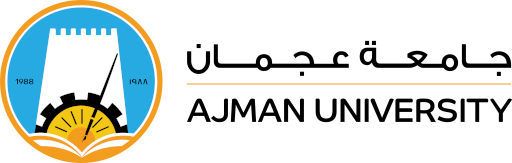

<p>
College: Engineering and Information Technology<br>
Department: Information Technology<br>
Program: Data Analytics<br>
Academic Semester: Spring 2025-2026<br>
Course: DAT405 Machine Learning Lab<br>
Course Instructor: Dr. Mahmoud AlShboul<br>
</p></center>

Student ID: ________________ <br />
Student Name: _________________

# **Lab 7 - Model Deployment**

Gradio is a Python library that lets you quickly build interactive web interfaces for your machine learning models, data processing functions, or any Python code — without writing any HTML, CSS, or JavaScript. It’s especially popular for AI demos, ML model testing, and sharing models with others through a simple web app. Gradio lets you:

- Create a GUI (Graphical User Interface) in just a few lines of Python.

- Test your models interactively (e.g., upload an image, enter text, or adjust sliders).

- Share your model via a public URL — others can try your model in their browser.

- Integrate easily with Hugging Face, TensorFlow, PyTorch, or Scikit-learn models.

In [ ]:
!pip install -q gradio

## Setting up an image classification model

In this step, we will use a pretrained mobileNet model from keras for image classification.

In [2]:
import tensorflow as tf
# Imports the TensorFlow library, which is a powerful framework for building and training deep learning models.
# It includes built-in modules for neural networks, computer vision, natural language processing, and more.

inception_net = tf.keras.applications.MobileNetV2()
# Loads the pre-trained MobileNetV2 model from TensorFlow’s Keras Applications module.
# MobileNetV2 is a lightweight convolutional neural network (CNN) architecture optimized for mobile and embedded vision applications.
# By default, it downloads weights pre-trained on the ImageNet dataset (a large dataset with 1,000 image categories).
# This makes the model capable of recognizing a wide variety of everyday objects right away.
# The model expects input images of shape (224, 224, 3) and outputs predictions for 1,000 ImageNet classes.


14536120/14536120 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


### Defining a predict function
The function will take user input, which would be an image, and returns the predictions. The predictions should be returned as a dictionary whose keys are clss names and values are confidence probabilities, the class names are fetched from this text file:
https://raw.githubusercontent.com/gradio-app/mobilenet-example/master/labels.txt

In [3]:
import requests
# Imports the 'requests' library, which allows you to make HTTP requests (e.g., download data from a URL).
# It's used here to fetch the class labels (names of objects) associated with the ImageNet dataset.


# Download the class labels
response = requests.get("https://raw.githubusercontent.com/gradio-app/mobilenet-example/master/labels.txt")
# Sends an HTTP GET request to the provided URL and retrieves the content (a text file with 1,000 class labels for ImageNet).
# Each label corresponds to one output neuron of the MobileNetV2 model.

labels = response.text.split("\n")
# The text file is a single string with labels separated by newlines ("\n").
# This line splits the text into a Python list, where each element is one label (e.g., "tench", "goldfish", "great white shark", ...).
# The resulting 'labels' list will have 1,000 elements.


# Creating a classification function that takes an image as input and returns a confidence probability value
def classify_image(inp):
    # 'inp' is expected to be an image (usually a NumPy array of shape (224, 224, 3)).

    inp = inp.reshape((-1, 224, 224, 3))
    # Reshapes the input image into a 4D tensor (batch of images) because Keras models expect inputs in batches.
    # '-1' means the batch size is inferred automatically (typically 1 in this case).
    # Final shape = (1, 224, 224, 3)

    inp = tf.keras.applications.mobilenet_v2.preprocess_input(inp)
    # Applies MobileNetV2-specific preprocessing to the input image.
    # This scales pixel values from [0, 255] to a range suitable for the model (typically [-1, 1]).
    # Proper preprocessing is crucial to get accurate predictions.

    prediction = inception_net.predict(inp).flatten()
    # Runs the image through the MobileNetV2 model to generate predictions.
    # The output is a vector of 1,000 confidence scores — one for each ImageNet class.
    # '.flatten()' converts it from a 2D array (e.g., [[...values...]]) to a 1D array for easier processing.

    confidences = {labels[i]: float(prediction[i]) for i in range(1000)}
    # Creates a dictionary mapping each class label to its corresponding confidence score.
    # Example: {'dog': 0.6, 'cat': 0.3, 'car': 0.1, ...}
    # The 'float()' ensures the values are standard Python floats instead of NumPy types (useful for serialization).

    return confidences
    # Returns the dictionary of all class probabilities.
    # This can later be sorted to find the most likely predicted class.


### Creating the interface (Using Gradio)

In [ ]:
import gradio as gr
# Imports the Gradio library — a Python package for quickly creating shareable web apps
# for machine learning models, without needing HTML, JavaScript, or Flask setup.
# It provides interactive UIs to test your models in seconds.

gr.Interface(
    fn=classify_image,
    # The function to be called when the user interacts with the interface.
    # Here, it's the 'classify_image' function we defined earlier.
    # It takes an image as input and returns confidence scores for 1,000 ImageNet classes.

    inputs=gr.Image(width=224, height=224),
    # Defines the type of input the web app expects — in this case, an image.
    # Gradio automatically provides an upload area or a webcam input in the browser.
    # width=224 and height=224 ensures the uploaded image is resized to 224x224 pixels,
    # matching the input requirements of the MobileNetV2 model.

    outputs=gr.Label(num_top_classes=3)
    # Defines the type of output to display.
    # 'gr.Label' creates a labeled confidence table showing predicted classes.
    # 'num_top_classes=3' means only the top 3 most confident class predictions are displayed to the user.

).launch(
    share=True,
    # Starts a local web server and also creates a temporary **public shareable link**
    # (useful for sharing with others or for demo purposes without deploying to a cloud service).

    debug=True
    # Enables debug mode — helpful if something goes wrong (e.g., shape mismatch, preprocessing errors).
    # It shows detailed error messages in the terminal or browser console.
)


## Model deployment on Huggingface

### Step 1: Prepare your files

You only need two files in total:

- app.py → your main Gradio app
- requirements.txt → list your dependencies

### Step 2: Create a Hugging Face account

If you don’t already have one: https://huggingface.co/join

### Step 3: Create a new Space

- Go to https://huggingface.co/spaces
- Click “+ New Space”
- Fill out:
  - Space name: e.g. mobilenetv2-image-classifier
  - License: choose any (MIT is fine)
  - SDK: select Gradio
  - Runtime: choose Python 3.10+
  - Visibility: Public (free) or Private (paid)
- Then click Create Space.

### Step 4: Upload your files

Once the Space is created:

- Drag and drop your files (app.py, requirements.txt) directly into the Hugging Face web editor.
- Wait for the build

After pushing your files, Hugging Face will automatically:

- Create a virtual environment
- Install dependencies from requirements.txt
- Launch your Gradio app

When it’s ready, you’ll see “Running” and a public URL like:

https://huggingface.co/spaces/YOUR_USERNAME/mobilenetv2-image-classifier

You can now share this link publicly.


In [ ]:
# app.py

import tensorflow as tf
import requests
import gradio as gr

# Load the pretrained MobileNetV2 model
model = tf.keras.applications.MobileNetV2()

# Download class labels (ImageNet classes)
response = requests.get("https://raw.githubusercontent.com/gradio-app/mobilenet-example/master/labels.txt")
labels = response.text.split("\n")

# Define the classification function
def classify_image(inp):
    inp = inp.reshape((-1, 224, 224, 3))
    inp = tf.keras.applications.mobilenet_v2.preprocess_input(inp)
    prediction = model.predict(inp).flatten()
    confidences = {labels[i]: float(prediction[i]) for i in range(1000)}
    return confidences

# Build Gradio interface
demo = gr.Interface(
    fn=classify_image,
    inputs=gr.Image(width=224, height=224),
    outputs=gr.Label(num_top_classes=3),
    title="Image Classifier (MobileNetV2)",
    description="Upload an image and get top-3 predictions from MobileNetV2 trained on ImageNet."
)

# Launch (for Hugging Face Spaces, no need for share=True)
if __name__ == "__main__":
    demo.launch()


In [ ]:
# requirements.txt

tensorflow
requests
gradio

# Question:

Use another pretrained model from the keras library to classify the images in the folder. Deploy the model to Huggingface.